In [2]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path("/scratch/jczhang/submeso_data_driven").resolve()))

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
# utils
from src.utils import read_mitgcm
from src.utils import build_coarse_grid
from src.utils import var_isopycnal

# data path
path_scratch = '/scratch/jczhang/'
path = 'MITgcm_baroclinic_instability_old/MITgcm/verification/tutorial_reentrant_channel/run/'
ds_grid = read_mitgcm.read_mitgrid_staggered(path_scratch + path)
# time averaging (3 months - 311040 time step = 2160 data points)
t_start = 15300000
window = 311040
ind_gap = 144 * 24


iters = np.arange(t_start, t_start + window + 1, ind_gap, dtype=np.int64)

ds_list = []
for it in iters:
    ds = read_mitgcm._ocean_var(path_scratch + path, "T", int(it), ("k","j","i"))
    ds = ds.expand_dims(time=[int(it)])
    ds_list.append(ds)

ds_T = xr.concat(ds_list, dim="time")
print(ds_T)


<xarray.DataArray 'T' (time: 91, k: 49, j: 1200, i: 600)> Size: 26GB
array([[[[0.        , 0.        , 0.        , ..., 0.        ,
          0.        , 0.        ],
         [0.        , 0.        , 0.        , ..., 0.        ,
          0.        , 0.        ],
         [0.        , 0.        , 0.        , ..., 0.        ,
          0.        , 0.        ],
         ...,
         [5.90719414, 5.90563965, 5.9049139 , ..., 5.90988827,
          5.910007  , 5.90893507],
         [5.89966011, 5.90051508, 5.90185785, ..., 5.89658976,
          5.89797735, 5.89895344],
         [5.89477253, 5.8945055 , 5.89430189, ..., 5.89501715,
          5.8949852 , 5.89497137]],

        [[0.        , 0.        , 0.        , ..., 0.        ,
          0.        , 0.        ],
         [0.        , 0.        , 0.        , ..., 0.        ,
          0.        , 0.        ],
         [0.        , 0.        , 0.        , ..., 0.        ,
          0.        , 0.        ],
...
         [0.53144491, 0.53165

In [8]:
from src.utils import var_isopycnal
import importlib
importlib.reload(var_isopycnal)
ds = xr.Dataset(dict(T = ds_T))
Tbar, dTdy, dTdz, slope = var_isopycnal.isotherm_slope(ds_grid, ds)

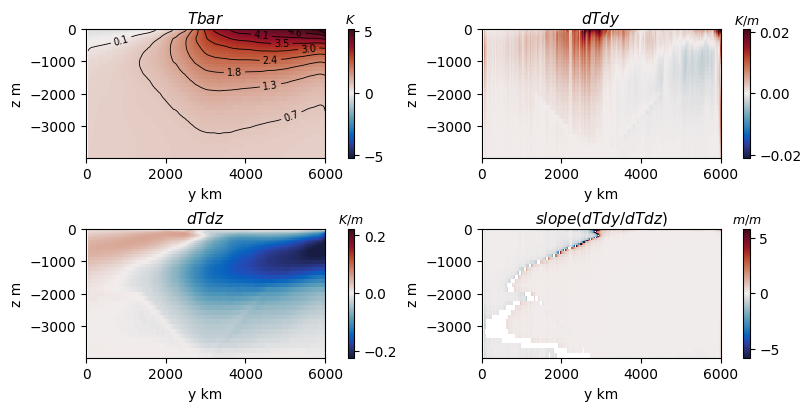

In [29]:
# path issue
import sys
from pathlib import Path
sys.path.insert(0, str(Path("/scratch/jczhang/submeso_data_driven").resolve()))
# check the velocity field and vorticity field
import numpy as np
import xarray as xr
from src.utils import read_mitgcm
from src.utils import build_coarse_grid
from src.utils import wT_total
from src.utils import make_grid
from src.utils import coarsen_UVWTS
from src.utils import mld_avg
import importlib

from matplotlib.colors import TwoSlopeNorm
from matplotlib.colors import Normalize
import cmocean.cm as cmo
import h5netcdf

from MITgcmutils import mds
import matplotlib.pyplot as plt

# 

def sym_limits(Z, q = 0.995):
    v = np.nanquantile(np.abs(Z), q)
    return float(v)

def pos_limits(Z, q=0.995):
    v = np.nanquantile(Z, q)
    return float(v)

def range_limits(Z, q = 0.995):
    """Return (vmin, vmax) from lower/upper quantiles."""
    vmin = np.nanquantile(Z, 1 - q)   # e.g. 0.5% if q=0.995
    vmax = np.nanquantile(Z, q)       # e.g. 99.5%
    return float(vmin), float(vmax)
slope_plot = slope.where(np.abs(dTdz) > 0.001)  # K/m threshold — tune this
# plot 
XC = ds_grid["RC"]
YC = ds_grid["YC"]
fields = {
    r"$Tbar$":         {"Z": Tbar,  "units": r"$K$",  "kind": "signed", "cmap": cmo.balance, "XC": XC, "YC":YC/1e3},
    r"$dTdy$":         {"Z": dTdy,  "units": r"$K/m$",  "kind": "signed", "cmap": cmo.balance, "XC": XC, "YC":YC/1e3},
    r"$dTdz$":         {"Z": dTdz,  "units": r"$K/m$",  "kind": "signed", "cmap": cmo.balance, "XC": XC, "YC":YC/1e3},
    r"$slope(dTdy/dTdz)$":         {"Z": slope_plot,  "units": r"$m/m$",  "kind": "signed", "cmap": cmo.balance, "XC": XC, "YC":YC/1e3},
    
}     



# Compute norms/limits per field
for key, meta in fields.items():   
    Z = meta["Z"]
    if meta["kind"] == "signed":
        q = sym_limits(Z)
        meta["norm"] = TwoSlopeNorm(vcenter=0.0, vmin=-q, vmax=+q)
    elif meta["kind"] == "positive":
        vmin, vmax = range_limits(Z)
        meta["norm"] = Normalize(vmin=vmin, vmax=vmax)
    elif meta["kind"] == "seq":
        meta["norm"] = Normalize(vmin=np.nanmin(Z), vmax=np.nanmax(Z))
    else:
        meta["norm"] = None
# Plot: 2×5
fig, axes = plt.subplots(2,2, figsize=(8, 4), constrained_layout=True)
# --- dynamic number of panels ---
n_fields = len(fields)
# if only one panel
if n_fields == 1:
    axes = np.array([axes])
axes = axes.ravel()

for ax, (title, meta) in zip(axes, fields.items()):
    Z = meta["Z"]
    cmap = meta["cmap"]
    norm = meta["norm"]
    XX = meta["XC"]                      # RC (z, m)
    YY = meta["YC"].isel(i=0).values     # y (km)

    pc = ax.pcolormesh(YY, XX, Z, shading='auto', cmap=cmap, norm=norm)

    # ---- add contours ONLY for Tbar ----
    if title == r"$Tbar$":
        Zc = Z.values
        # pick contour levels (avoid too many)
        vmin = float(np.nanmin(Zc))
        vmax = float(np.nanmax(Zc))
        levels = np.linspace(vmin, vmax, 12)  # 8–15 is usually nice

        cs = ax.contour(YY, XX, Zc, levels=levels, colors="k", linewidths=0.6)
        ax.clabel(cs, inline=True, fontsize=7, fmt="%.1f")

    ax.set_title(title, fontsize=11, pad=4)
    ax.set_xlabel('y km'); ax.set_ylabel('z m')

    cb = fig.colorbar(pc, ax=ax, pad=0.02)
    cb.ax.set_title(meta["units"], pad=4, fontsize=9)

# fig.savefig("./temperature_gradient.png")
plt.show()